# Nhận dạng hoạt động từ PPG và ACC — E1–E6

Tải PPG-DaLiA → tiền xử lý → 6 model, **seed 42** → 6 confusion matrix trên Test.

- Train **S1–S10**, Validation **S11–S12**, Test **S13–S15**; không chia ngẫu nhiên các cửa sổ.
- Cửa sổ **8 giây**, bước **2 giây**. Bỏ cửa sổ có nhãn 0 hoặc độ thuần nhãn dưới 80%.
- PPG 64 Hz hạ về 32 Hz; ACC 32 Hz. Mean/std chỉ tính trên Train.
- Chọn checkpoint và tham số EMA bằng Validation. Test đã được xem trong quá trình phát triển trước đây.

| Model | Đầu vào và phương pháp |
|---|---|
| E1 | Random Forest, 38 đặc trưng PPG + ACC |
| E2 | CNN 1D, PPG + ACC |
| E3 | CNN 2D STFT, PPG + ACC |
| E4 | CNN 2D STFT, chỉ ACC |
| E5 | CNN 2D STFT, chỉ PPG |
| E6 | CNN 1D MultiKernel, Mixup khi train, causal EMA khi đánh giá |

Mặc định dùng checkpoint và prediction đã lưu nếu có. Đặt `RETRAIN = True` để train và dự đoán lại.
Các lượt mới lưu riêng trong `artifacts/compact/`, không ghi đè checkpoint gốc.
Code train E6 được viết gọn lại theo cấu hình đã lưu; seed 42 không bảo đảm tái tạo chính xác trọng số cũ trên mọi máy.

## 1. Import và cấu hình

In [ ]:
import json
import pickle
import random
import shutil
import zipfile
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from scipy import signal
from scipy.interpolate import RegularGridInterpolator
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Chạy được từ thư mục repo, source hoặc notebooks.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif (ROOT / "source/notebooks").is_dir():
    ROOT = ROOT / "source"

ART = ROOT / "artifacts"
RAW = ROOT / "data/raw"
DATA = ART / "compact/data"
RUN = ART / "compact" / datetime.now().strftime("run-%Y%m%d-%H%M%S-%f")
SEED = 42
RETRAIN = False
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
SPLITS = {"train": list(range(1, 11)), "validation": [11, 12], "test": [13, 14, 15]}
LABELS = ["Ngồi yên", "Cầu thang", "Bi lắc", "Đạp xe", "Lái ô tô", "Nghỉ/ăn trưa", "Đi bộ", "Làm việc"]
EXPERIMENTS = {"E2": ("cnn1d", [0, 1, 2, 3]), "E3": ("cnn2d", [0, 1, 2, 3]),
               "E4": ("cnn2d", [1, 2, 3]), "E5": ("cnn2d", [0]), "E6": ("multikernel", [0, 1, 2, 3])}
BATCH_SIZE = 128
models = {}
checkpoint_paths = {}


def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


set_seed()


## 2. Tải PPG-DaLiA

Dùng cùng mirror Kaggle của bản trước. ZIP khoảng 3,14 GB; chỉ giải nén 15 file pickle đồng bộ (khoảng 22 GB).
Không tải lại file đã có. Pickle chỉ đọc từ nguồn dataset này.

In [ ]:
def download_data():
    RAW.mkdir(parents=True, exist_ok=True)
    subjects = [f"S{i}.pkl" for i in range(1, 16)]
    if all(any(RAW.rglob(name)) for name in subjects):
        return
    archive = RAW / "ppg-dalia.zip"
    url = "https://www.kaggle.com/api/v1/datasets/download/aiforiot/ppg-dalia"
    if not archive.exists():
        temporary = archive.with_suffix(".part")
        with requests.get(url, stream=True, timeout=60) as response:
            response.raise_for_status()
            with temporary.open("wb") as output:
                for block in response.iter_content(1024 * 1024):
                    output.write(block)
        temporary.replace(archive)
    with zipfile.ZipFile(archive) as zipped:
        entries = {Path(name).name: name for name in zipped.namelist() if Path(name).name in subjects}
        if set(entries) != set(subjects):
            raise ValueError("ZIP không chứa đủ 15 file S1.pkl–S15.pkl.")
        for name in subjects:
            if any(RAW.rglob(name)):
                continue
            target = RAW / "PPG_FieldStudy" / name[:-4] / name
            target.parent.mkdir(parents=True, exist_ok=True)
            temporary = target.with_suffix(".part")
            with zipped.open(entries[name]) as source, temporary.open("wb") as output:
                shutil.copyfileobj(source, output)  # ZipFile kiểm tra CRC khi đọc hết file.
            temporary.replace(target)


download_data()


## 3. Tiền xử lý

Đọc từng người, tạo cửa sổ rồi ghép theo split. Nhãn 1–8 được đổi thành 0–7.

In [ ]:
def read_subject(subject):
    path = next(RAW.rglob(f"S{subject}.pkl"))
    with path.open("rb") as stream:
        data = pickle.load(stream, encoding="latin1")
    assert str(data["subject"]).lstrip("S") == str(subject)
    wrist = data["signal"]["wrist"]
    ppg = np.asarray(wrist["BVP"]).reshape(-1)
    acc = np.asarray(wrist["ACC"])
    activity = np.asarray(data["activity"]).reshape(-1)
    durations = [len(ppg) / 64, len(acc) / 32, len(activity) / 4]
    assert acc.ndim == 2 and acc.shape[1] == 3
    assert max(durations) - min(durations) <= 0.25
    assert np.isin(activity, np.arange(9)).all()
    windows, labels, ids = [], [], []
    count = max(0, int((min(durations) - 8) // 2) + 1)
    for j in range(count):
        p = ppg[j * 128:j * 128 + 512]
        a = acc[j * 64:j * 64 + 256].T
        y = activity[j * 8:j * 8 + 32].astype(int)
        if p.size != 512 or a.shape != (3, 256) or y.size != 32:
            continue
        if not (np.isfinite(p).all() and np.isfinite(a).all()) or (y == 0).any():
            continue
        counts = np.bincount(y, minlength=9)
        label = counts[1:].argmax() + 1
        if counts[label] / 32 < 0.8:
            continue
        # Lọc chống aliasing trong từng cửa sổ, không cắt S6 thêm lần nữa.
        p = signal.decimate(p.astype("float32"), 2, n=8, ftype="iir", zero_phase=True)
        windows.append(np.concatenate([p[None], a.astype("float32")]))
        labels.append(label - 1)
        ids.append(f"S{subject:02d}_W{j:06d}")
    if not windows:
        raise ValueError(f"S{subject} không có cửa sổ hợp lệ.")
    return {"x": np.asarray(windows, dtype="float32"), "y": np.asarray(labels, dtype="int64"),
            "subject": np.full(len(labels), subject, dtype="int64"), "window_id": np.asarray(ids)}


### 38 đặc trưng cho E1

28 thống kê trên 4 kênh + 8 band power của PPG/độ lớn ACC + 2 tần số đỉnh.

In [ ]:
BANDS = [(0.5, 2), (2, 4), (4, 8), (8, 12)]

def features(x):
    """38 đặc trưng theo thứ tự cố định; đầu vào chưa chuẩn hóa."""
    x = np.asarray(x, dtype="float64")
    mean, std = x.mean(-1), x.std(-1)
    centered = x - mean[..., None]
    # Kiểm tra min=max để tránh round-off của std trên tín hiệu hằng.
    constant = np.ptp(x, axis=-1) == 0
    safe_std = np.where(constant, 1, std)
    kurt = (centered**4).mean(-1) / safe_std**4 - 3
    kurt = np.where(constant, 0, kurt)
    signs = centered >= 0
    zcr = (signs[..., 1:] != signs[..., :-1]).mean(-1)
    stats = np.stack(
        [mean, std, x.min(-1), x.max(-1), np.sqrt((x * x).mean(-1)), kurt, zcr], axis=-1
    )
    stats = stats.reshape(*x.shape[:-2], 28)
    mag = np.sqrt((x[..., 1:, :] ** 2).sum(-2))
    waves = np.stack([x[..., 0, :], mag], axis=-2)
    f, psd = signal.welch(
        waves,
        fs=32,
        window="hann",
        nperseg=128,
        noverlap=64,
        nfft=128,
        detrend="constant",
        scaling="density",
        axis=-1,
    )
    power = []
    for lo, hi in BANDS:
        mask = (f >= lo) & ((f <= hi) if hi == 12 else (f < hi))
        power.append(psd[..., mask].sum(-1) * 0.25)
    power = np.stack(power, axis=-1).reshape(*x.shape[:-2], 8)
    mask = (f >= 0.5) & (f <= 12)
    peaks = f[mask][psd[..., mask].argmax(-1)]
    peaks = np.where(np.ptp(waves, axis=-1) == 0, 0, peaks)
    out = np.concatenate([stats, power, peaks], axis=-1).astype("float32")
    assert out.shape[-1] == 38
    assert np.isfinite(out).all()
    return out


### STFT cho E3–E5

Tín hiệu đã chuẩn hóa → STFT → log biên độ → nội suy về 32 × 32.

In [ ]:
def spectrogram(x):
    """STFT (...,C,256) -> (...,C,32,32), nội suy trên trục vật lý."""
    f, t, z = signal.stft(
        x,
        fs=32,
        window="hann",
        nperseg=64,
        noverlap=60,
        nfft=64,
        detrend=False,
        boundary=None,
        padded=False,
        scaling="spectrum",
        axis=-1,
    )
    assert z.shape[-2:] == (33, 49)
    assert np.allclose(t, np.arange(49) / 8 + 1)
    values = np.log1p(np.abs(z[..., :25, :]))
    # Interpolator yêu cầu hai trục cần nội suy đứng trước các trục batch/kênh.
    values = np.moveaxis(values, (-2, -1), (0, 1))
    grid = RegularGridInterpolator((f[:25], t), values, method="linear")
    ff, tt = np.meshgrid(np.linspace(0, 12, 32), np.linspace(1, 7, 32), indexing="ij")
    result = grid(np.stack([ff, tt], axis=-1))
    return np.moveaxis(result, (0, 1), (-2, -1)).astype("float32")


### Chuẩn bị dữ liệu một lần

Cache đầy đủ được dùng lại. Mean/std chỉ tính từ Train, không từ Validation hay Test.

In [ ]:
def prepare_data():
    required = [f"{split}_{key}.npy" for split in SPLITS
                for key in ["x", "z", "stft", "features", "y", "subject", "window_id"]]
    if (DATA / "ready.json").exists() and (DATA / "normalization.npz").exists() and all((DATA / name).exists() for name in required):
        return
    DATA.mkdir(parents=True, exist_ok=True)
    (DATA / "ready.json").unlink(missing_ok=True)
    for split, subjects in SPLITS.items():
        parts = [read_subject(subject) for subject in subjects]
        for key in ["x", "y", "subject", "window_id"]:
            np.save(DATA / f"{split}_{key}.npy", np.concatenate([part[key] for part in parts]))
        del parts
    train = np.load(DATA / "train_x.npy", mmap_mode="r")
    mean = train.mean(axis=(0, 2), dtype="float64").astype("float32")
    std = train.std(axis=(0, 2), dtype="float64").astype("float32")
    std[std < 1e-8] = 1
    np.savez(DATA / "normalization.npz", mean=mean, std=std)
    for split in SPLITS:
        x = np.load(DATA / f"{split}_x.npy", mmap_mode="r")
        z = np.lib.format.open_memmap(DATA / f"{split}_z.npy", mode="w+", dtype="float32", shape=x.shape)
        stft = np.lib.format.open_memmap(DATA / f"{split}_stft.npy", mode="w+", dtype="float32", shape=(len(x), 4, 32, 32))
        rf = np.lib.format.open_memmap(DATA / f"{split}_features.npy", mode="w+", dtype="float32", shape=(len(x), 38))
        for start in range(0, len(x), 512):
            batch = x[start:start + 512]
            normalized = (batch - mean[None, :, None]) / std[None, :, None]
            z[start:start + 512] = normalized
            stft[start:start + 512] = spectrogram(normalized)
            rf[start:start + 512] = features(batch)
        z.flush(); stft.flush(); rf.flush()
    (DATA / "ready.json").write_text(json.dumps({"split": SPLITS, "window_seconds": 8, "hop_seconds": 2}))


def load_split(split, representation):
    return (np.load(DATA / f"{split}_{representation}.npy", mmap_mode="r"),
            np.load(DATA / f"{split}_y.npy"), np.load(DATA / f"{split}_subject.npy"))


prepare_data()
pd.DataFrame([{"split": split, "windows": len(np.load(DATA / f"{split}_y.npy")), "subjects": subjects}
              for split, subjects in SPLITS.items()])


## 4. E1 — Random Forest, seed 42

Chọn depth và số mẫu tối thiểu ở lá theo Macro F1 trung bình của S11/S12.

In [ ]:
def selection_score(y, pred, subjects):
    return float(
        np.mean(
            [
                float(
                    f1_score(
                        y[subjects == s],
                        pred[subjects == s],
                        labels=range(8),
                        average="macro",
                        zero_division=0,
                    )
                )
                for s in np.unique(subjects)
            ]
        )
    )


In [ ]:
def train_rf():
    saved = ART / "models/E1/model.joblib"
    if not RETRAIN and saved.exists():
        checkpoint_paths["E1"] = saved
        return joblib.load(saved)
    set_seed()
    x, y, _ = load_split("train", "features")
    xv, yv, subjects = load_split("validation", "features")
    best_model, best_score = None, -1
    for depth in [10, 20, None]:
        for leaf in [1, 5]:
            model = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                           max_features="sqrt", class_weight="balanced", random_state=SEED, n_jobs=1)
            model.fit(x, y)
            score = selection_score(yv, model.predict(xv), subjects)
            if score > best_score:
                best_model, best_score = model, score
    output = RUN / "E1"
    output.mkdir(parents=True, exist_ok=True)
    joblib.dump(best_model, output / "model.joblib")
    checkpoint_paths["E1"] = output / "model.joblib"
    return best_model


models["E1"] = train_rf()


## 5. Kiến trúc CNN E2–E5

In [ ]:
def make_model(kind: str, channels: int) -> nn.Sequential:
    """CNN 1D cho chuỗi tín hiệu, CNN 2D cho ảnh STFT."""
    if kind == "cnn1d":
        return nn.Sequential(
            nn.Conv1d(channels, 16, 5, padding=2, bias=False),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 5, padding=2, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.Dropout(0.3),
            nn.Linear(32, 8),
        )
    if kind == "cnn2d":
        return nn.Sequential(
            nn.Conv2d(channels, 8, 3, padding=1, bias=False),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 24, 3, padding=1, bias=False),
            nn.BatchNorm2d(24),
            nn.ReLU(),
            nn.AvgPool2d(4),
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(96, 8),
        )
    raise ValueError(f"Kiến trúc không hợp lệ: {kind}")


## 6. Kiến trúc E6 — MultiKernel

Ba nhánh kernel 3/5/7, ghép kênh rồi cộng residual. Kiến trúc khớp checkpoint E6 hiện có.

In [ ]:
class MultiKernelBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.branches = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv1d(24, 8, 1, bias=False),
                    nn.BatchNorm1d(8),
                    nn.ELU(),
                    nn.Conv1d(8, 8, kernel, padding=kernel // 2, bias=False),
                    nn.BatchNorm1d(8),
                    nn.ELU(),
                )
                for kernel in [3, 5, 7]
            ]
        )
        self.project = nn.Sequential(
            nn.Conv1d(24, 24, 1, bias=False), nn.BatchNorm1d(24)
        )
        self.activation = nn.ELU()

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        combined = torch.cat([branch(inputs) for branch in self.branches], dim=1)
        return self.activation(inputs + self.project(combined))


def make_e6():
    return nn.Sequential(
        nn.Conv1d(4, 24, 7, padding=3, bias=False),
        nn.BatchNorm1d(24),
        nn.ELU(),
        nn.MaxPool1d(2),
        MultiKernelBlock(),
        nn.MaxPool1d(2),
        MultiKernelBlock(),
        nn.MaxPool1d(2),
        MultiKernelBlock(),
        nn.AdaptiveAvgPool1d(1),
        nn.Flatten(),
        nn.Dropout(0.3),
        nn.Linear(24, 8),
    )


## 7. Hàm train chung cho CNN

Weighted cross entropy; Adam LR 0,001, weight decay 0,0001; batch 128.
E2–E5: tối đa 50 epoch, patience 8. E6: tối đa 100 epoch, patience 20, Mixup α=0,2 và giảm LR theo Validation.
Chỉ chuyển từng batch lên GPU. Checkpoint tốt nhất dựa trên Macro F1 trung bình từng người Validation.

In [ ]:
def cnn_input(name, split):
    kind, channels = EXPERIMENTS[name]
    representation = "stft" if kind == "cnn2d" else "z"
    x, y, subjects = load_split(split, representation)
    return np.array(x[:, channels], copy=True), y, subjects


def predict(model, x):
    model.eval()
    outputs = []
    with torch.inference_mode():
        for start in range(0, len(x), 512):
            batch = torch.from_numpy(np.array(x[start:start + 512], dtype="float32", copy=True)).to(DEVICE)
            outputs.append(model(batch).cpu().numpy())
    return np.concatenate(outputs)


def train_cnn(name):
    set_seed()
    kind, channels = EXPERIMENTS[name]
    model = make_e6() if name == "E6" else make_model(kind, len(channels))
    saved = ART / "extension/model/best.pt" if name == "E6" else ART / f"models/{name}/seed_42/best.pt"
    if not RETRAIN and saved.exists():
        # Checkpoint cũ phải dùng cùng mean/std như cache vừa tạo.
        old_scale = ART / "extension/model/normalization.npz" if name == "E6" else ART / "data/normalization.npz"
        with np.load(old_scale) as old, np.load(DATA / "normalization.npz") as current:
            np.testing.assert_allclose(current["mean"], old["mean"], rtol=1e-5, atol=1e-6)
            np.testing.assert_allclose(current["std"], old["std"], rtol=1e-5, atol=1e-6)
        model.load_state_dict(torch.load(saved, map_location="cpu", weights_only=True))
        checkpoint_paths[name] = saved
        return model.to(DEVICE).eval()
    model.to(DEVICE)
    x, y, _ = cnn_input(name, "train")
    xv, yv, subjects = cnn_input(name, "validation")
    loader = DataLoader(TensorDataset(torch.from_numpy(x), torch.from_numpy(y)),
                        batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    counts = np.bincount(y, minlength=8)
    assert (counts > 0).all(), "Train thiếu lớp"
    weights = torch.tensor(len(y) / (8 * counts), dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.75,
                                                        patience=6, threshold=0.001, min_lr=1e-5)
    epochs, patience = (100, 20) if name == "E6" else (50, 8)
    output = RUN / name
    output.mkdir(parents=True, exist_ok=True)
    shutil.copy2(DATA / "normalization.npz", output / "normalization.npz")
    best_score, stale = -1, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        for batch, targets in loader:
            batch, targets = batch.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            if name == "E6":
                ratio = float(np.random.beta(0.2, 0.2))
                order = torch.randperm(len(batch), device=DEVICE)
                logits = model(ratio * batch + (1 - ratio) * batch[order])
                loss = ratio * criterion(logits, targets) + (1 - ratio) * criterion(logits, targets[order])
            else:
                loss = criterion(model(batch), targets)
            loss.backward()
            optimizer.step()
        score = selection_score(yv, predict(model, xv).argmax(1), subjects)
        history.append({"epoch": epoch, "validation_subject_macro_f1": score})
        if name == "E6":
            scheduler.step(score)
        if score > best_score:
            best_score, stale = score, 0
            state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            torch.save(state, output / "best.pt")
        else:
            stale += 1
        if stale >= patience:
            break
    pd.DataFrame(history).to_csv(output / "history.csv", index=False)
    checkpoint_paths[name] = output / "best.pt"
    model.load_state_dict(torch.load(output / "best.pt", map_location="cpu", weights_only=True))
    return model.eval()


### E2 — CNN 1D, PPG + ACC, seed 42

In [ ]:
models["E2"] = train_cnn("E2")


### E3 — CNN 2D STFT, PPG + ACC, seed 42

In [ ]:
models["E3"] = train_cnn("E3")


### E4 — CNN 2D STFT, ACC, seed 42

In [ ]:
models["E4"] = train_cnn("E4")


### E5 — CNN 2D STFT, PPG, seed 42

In [ ]:
models["E5"] = train_cnn("E5")


### E6 — MultiKernel + Mixup, seed 42

In [ ]:
models["E6"] = train_cnn("E6")


## 8. Causal EMA cho E6

Chỉ dùng xác suất hiện tại và quá khứ; reset khi đổi người hoặc khi hai cửa sổ không liền nhau.
Temperature/alpha của checkpoint gốc được đọc từ `selection.json`. Khi train E6 mới, chọn alpha trên Validation; temperature giữ 1.

In [ ]:
def smooth(probabilities, subjects, window_ids, alpha):
    output = np.empty_like(probabilities)
    previous = None
    for i, probability in enumerate(probabilities):
        window = int(str(window_ids[i]).split("_W")[1])
        reset = i == 0 or subjects[i] != subjects[i - 1] or previous is None or window != previous + 1
        memory = probability.copy() if reset else alpha * probability + (1 - alpha) * output[i - 1]
        output[i] = memory
        previous = window
    return output


def e6_postprocess():
    if checkpoint_paths["E6"] == ART / "extension/model/best.pt":
        return json.loads((ART / "extension/selection.json").read_text())["postprocess"]
    x, y, subjects = cnn_input("E6", "validation")
    probabilities = softmax(predict(models["E6"], x), axis=1)
    ids = np.load(DATA / "validation_window_id.npy")
    best_alpha, best_score = 1.0, -1
    for alpha in [0.2, 0.35, 0.5, 0.75, 1.0]:
        pred = smooth(probabilities, subjects, ids, alpha).argmax(1)
        score = selection_score(y, pred, subjects)
        if score > best_score:
            best_alpha, best_score = alpha, score
    post = {"temperature": 1.0, "ema_alpha": best_alpha}
    (checkpoint_paths["E6"].parent / "postprocess.json").write_text(json.dumps(post))
    return post


## 9. confusion matrix trên Test — seed 42

Hàng = nhãn thật, cột = dự đoán; ô là số cửa sổ. Test gồm S13–S15.
E1–E5 dùng dự đoán trực tiếp; E6 dùng causal EMA.
Nếu đang dùng đúng checkpoint gốc và có CSV prediction đi kèm, đọc lại CSV đó; nếu train mới thì suy luận trên Test.
Dòng dưới mỗi hình ghi rõ nguồn kết quả. Đây là kết quả trên máy tính, không phải phép đo mới trên ESP32.

In [ ]:
def test_predictions(name):
    saved_model = ART / "models/E1/model.joblib" if name == "E1" else ART / f"models/{name}/seed_42/best.pt"
    saved_csv = ART / f"results/{name}_42_predictions.csv"
    if name == "E6":
        saved_model = ART / "extension/model/best.pt"
        saved_csv = ART / "extension/evaluation/dalia_ema_predictions.csv"
    if not RETRAIN and checkpoint_paths[name] == saved_model and saved_csv.exists():
        frame = pd.read_csv(saved_csv).rename(columns={"y": "true_label", "prediction": "predicted_label", "session": "subject_id"})
        if (DATA / "test_window_id.npy").exists():
            np.testing.assert_array_equal(frame.window_id.to_numpy(), np.load(DATA / "test_window_id.npy"))
            np.testing.assert_array_equal(frame.true_label.to_numpy(), np.load(DATA / "test_y.npy"))
        return frame, "Prediction đã lưu của checkpoint gốc"
    if name == "E1":
        x, y, subjects = load_split("test", "features")
        predicted = models[name].predict(x)
    else:
        x, y, subjects = cnn_input(name, "test")
        logits = predict(models[name], x)
        if name == "E6":
            post = e6_postprocess()
            probabilities = softmax(logits / post["temperature"], axis=1)
            probabilities = smooth(probabilities, subjects, np.load(DATA / "test_window_id.npy"), post["ema_alpha"])
            predicted = probabilities.argmax(1)
        else:
            predicted = logits.argmax(1)
    frame = pd.DataFrame({"window_id": np.load(DATA / "test_window_id.npy"), "subject_id": subjects,
                          "true_label": y, "predicted_label": predicted})
    RUN.mkdir(parents=True, exist_ok=True)
    frame.to_csv(RUN / f"{name}_42_predictions.csv", index=False)
    return frame, "Suy luận lại từ checkpoint của lượt này"


def show_confusion(name):
    frame, source = test_predictions(name)
    assert set(frame.subject_id.astype(int)) == set(SPLITS["test"])
    assert frame.window_id.is_unique
    y, predicted = frame.true_label.to_numpy(), frame.predicted_label.to_numpy()
    matrix = confusion_matrix(y, predicted, labels=range(8))
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.tick_params(axis="x", labelrotation=45)
    mode = " + causal EMA" if name == "E6" else ""
    ax.set(title=f"{name}{mode} · seed 42 · Test S13–S15", xlabel="Dự đoán", ylabel="Nhãn thật")
    accuracy = accuracy_score(y, predicted)
    f1 = f1_score(y, predicted, labels=range(8), average="macro", zero_division=0)
    fig.text(0.5, 0.01, f"Accuracy {accuracy:.2%} · Macro F1 {f1:.2%} · {len(y):,} cửa sổ", ha="center")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()
    print(source)


### E1 — confusion matrix Test

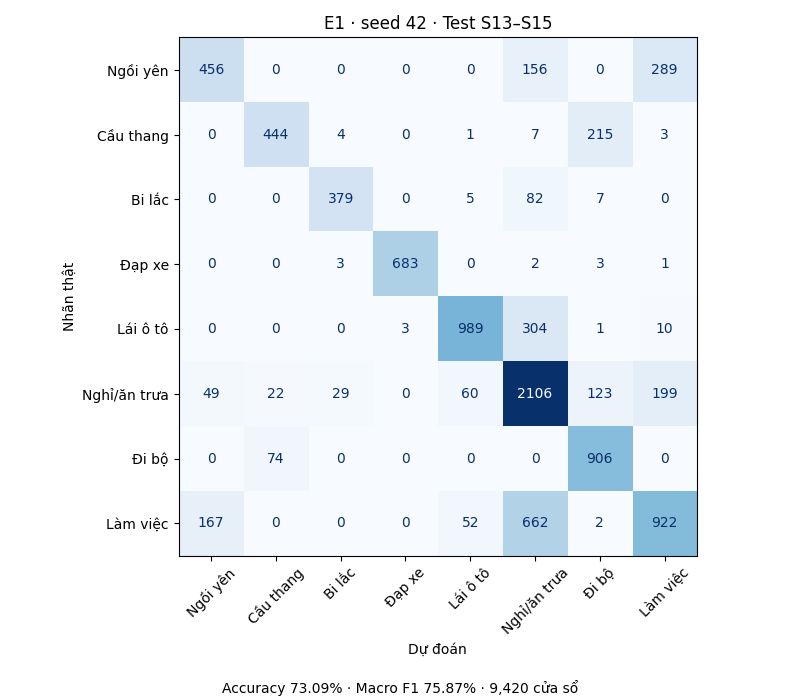

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E1")


### E2 — confusion matrix Test

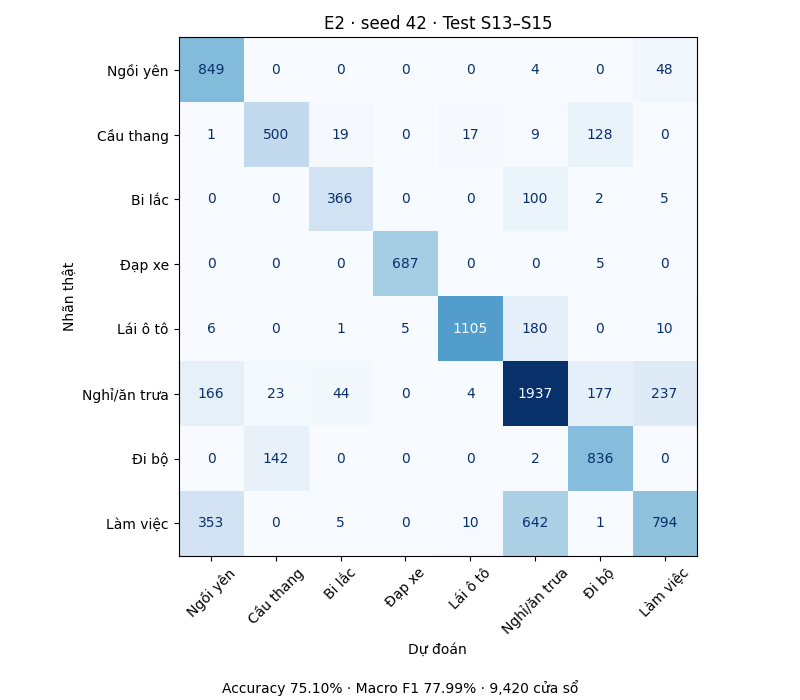

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E2")


### E3 — confusion matrix Test

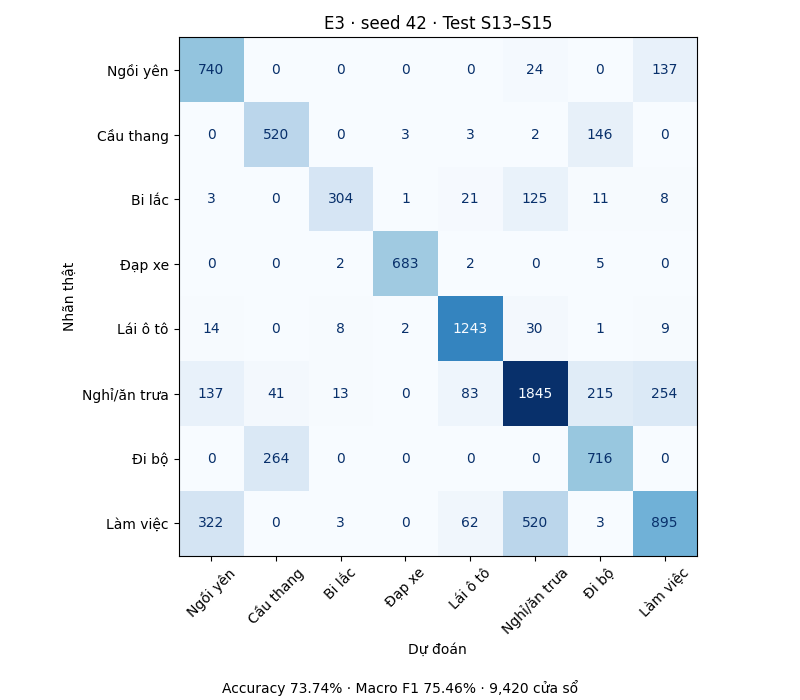

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E3")


### E4 — confusion matrix Test

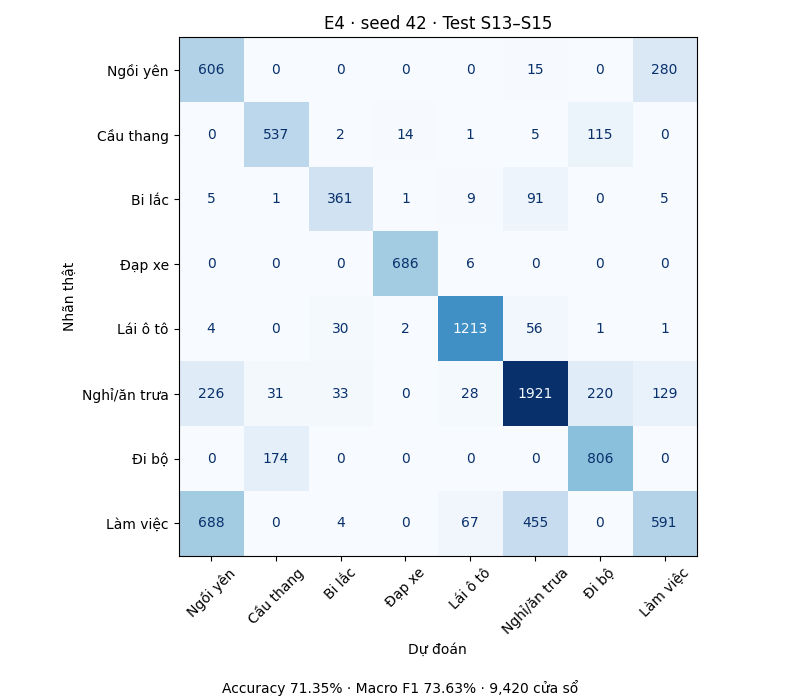

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E4")


### E5 — confusion matrix Test

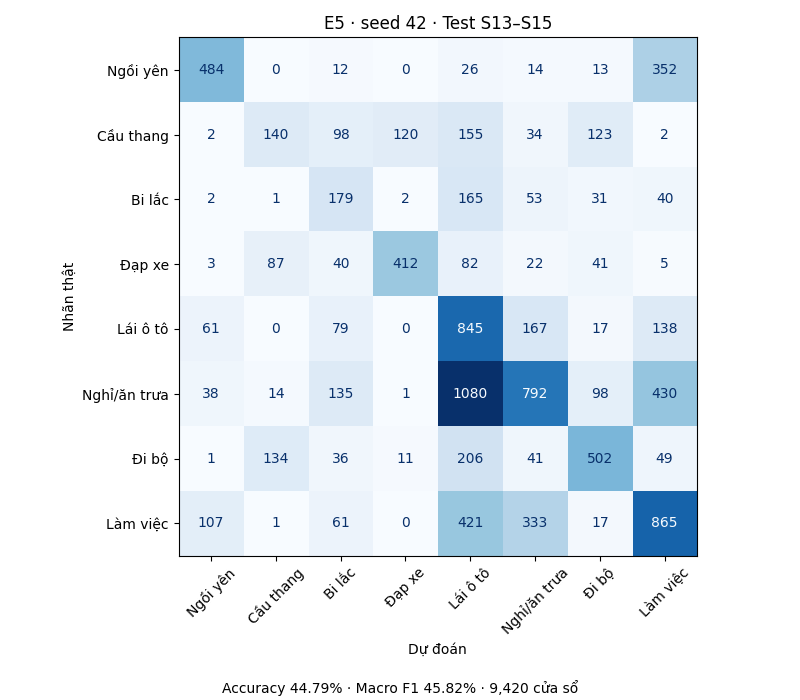

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E5")


### E6 — confusion matrix Test

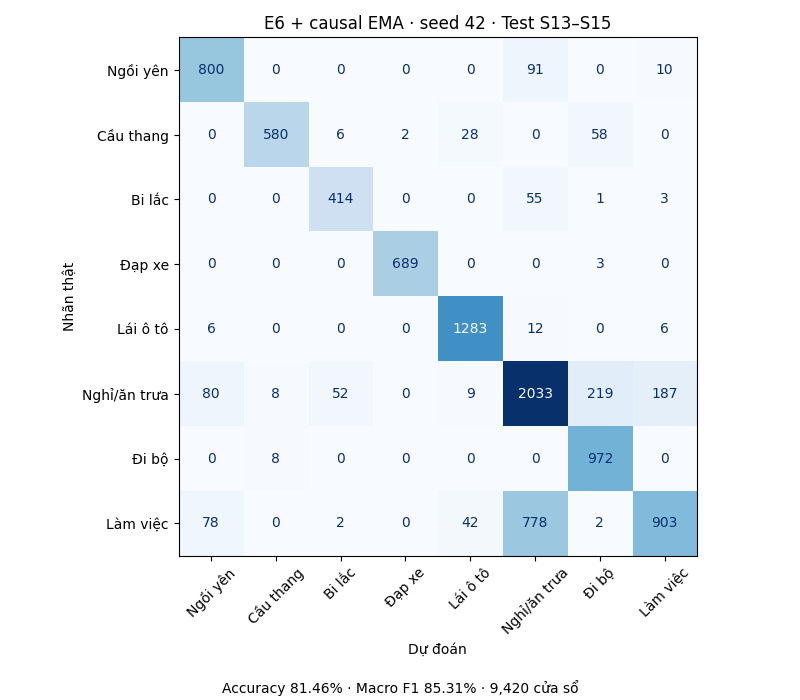

Prediction đã lưu của checkpoint gốc


In [ ]:
show_confusion("E6")
